🚀 Ingesting real-time market metrics...
⚙️ Training LightGBM Optimization Engine...
🔮 Initializing SHAP Explainability Engine...

--- Live Production Log: Simulated Microservice API Output ---
{
    "status": "Success",
    "predicted_optimal_price": 197.57,
    "base_value_reference": 218.48,
    "feature_impact_breakdown": {
        "base_price": -16.0958,
        "competitor_price": -27.5185,
        "inventory_level": 8.8091,
        "demand_score": -8.0851,
        "day_of_week": -0.258,
        "is_holiday": 22.2374
    }
}


C:\Users\Rahul Singh\AppData\Local\Temp\ipykernel_11716\2791627941.py:102: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_scaled_df)


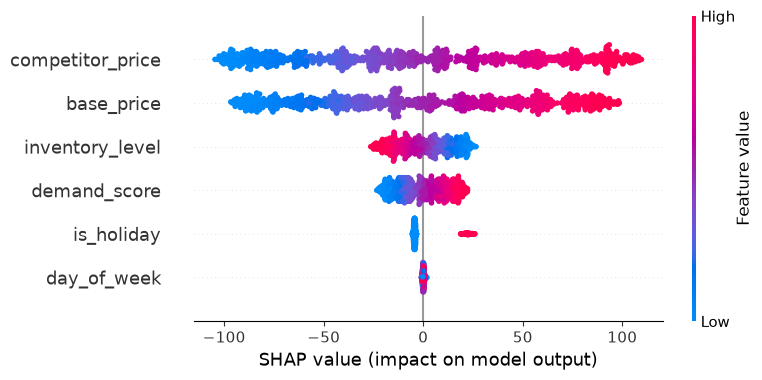

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import shap
import json

# 1. SIMULATE REAL-TIME FINTECH/RETAIL TRANSACTION DATA
def generate_mock_fintech_data(n_samples=5000):
    np.random.seed(42)
    data = {
        'base_price': np.random.uniform(10, 500, n_samples),
        'competitor_price': np.random.uniform(8, 550, n_samples),
        'inventory_level': np.random.randint(5, 1000, n_samples),
        'demand_score': np.random.uniform(0.1, 1.0, n_samples),
        'day_of_week': np.random.randint(0, 7, n_samples),
        'is_holiday': np.random.choice([0, 1], n_samples, p=[0.85, 0.15])
    }
    df = pd.DataFrame(data)
    
    # Calculate optimal dynamic price using a complex financial logic (Target Variable)
    # Price increases if demand is high, inventory is low, or competitor price is high
    df['optimal_dynamic_price'] = (
        df['base_price'] * 0.4 + 
        df['competitor_price'] * 0.4 + 
        (1.0 - df['demand_score']) * -50 + 
        (1000 - df['inventory_level']) * 0.05 + 
        df['is_holiday'] * 30 + 
        np.random.normal(0, 10, n_samples)
    )
    return df

# Ingesting clean structured data
print("🚀 Ingesting real-time market metrics...")
df_finance = generate_mock_fintech_data()

X = df_finance.drop(columns=['optimal_dynamic_price'])
y = df_finance['optimal_dynamic_price']

# 2. MACHINE LEARNING PIPELINE WITH PREPROCESSING
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame to preserve feature headers for SHAP explainability
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

# 3. TRAIN LIGHTGBM REGRESSOR (FinTech Industry Standard for Speed & Accuracy)
print("⚙️ Training LightGBM Optimization Engine...")
train_data = lgb.Dataset(X_train_scaled_df, label=y_train)
test_data = lgb.Dataset(X_test_scaled_df, label=y_test, reference=train_data)

params = {
    'objective': 'regression',
    'metric': 'rmse',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'verbose': -1
}

model = lgb.train(
    params,
    train_data,
    num_boost_round=200,
    valid_sets=[test_data]
)

# 4. EXPLAINABLE AI (XAI) LAYER VIA SHAP
print("🔮 Initializing SHAP Explainability Engine...")
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test_scaled_df)

# Production API Function: Explains exactly why a transaction price was chosen
def explain_financial_decision(sample_index=0):
    """
    Simulates a microservice endpoint that outputs the exact financial 
    reasons behind a specific price adjustment.
    """
    single_sample = X_test_scaled_df.iloc[[sample_index]]
    prediction = model.predict(single_sample)[0]
    
    # Extract feature contributions for this specific transaction
    sample_shap = explainer(single_sample)
    contributions = dict(zip(X.columns, sample_shap.values[0]))
    
    explanation_output = {
        "status": "Success",
        "predicted_optimal_price": round(float(prediction), 2),
        "base_value_reference": round(float(sample_shap.base_values[0]), 2),
        "feature_impact_breakdown": {k: round(float(v), 4) for k, v in contributions.items()}
    }
    return json.dumps(explanation_output, indent=4)

# Test the explanation microservice
print("\n--- Live Production Log: Simulated Microservice API Output ---")
print(explain_financial_decision(sample_index=5))
shap.summary_plot(shap_values, X_test_scaled_df)
